# Matrices and Linear Systems

**AI Mathematics · 1. Linear Algebra**

Learn matrix operations, linear systems, rank, determinant, and why solving is usually better than explicitly inverting a matrix.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Distinguish elementwise operations from matrix multiplication.
- Use transpose, rank, determinant, and linear-system solvers.
- Understand singular and ill-conditioned systems.

In [1]:
import numpy as np

## 1. Matrix basics and shapes
A matrix is a rectangular array. If \(A\) has shape \((m,n)\), it maps an \(n\)-dimensional vector to an \(m\)-dimensional vector when the product is defined.

In [2]:
import numpy as np

A = np.array([[1.0, 2.0], [3.0, 4.0]])
B = np.array([[10.0, 20.0], [30.0, 40.0]])
print("shape:", A.shape)
print("elementwise A * B:\n", A * B)
print("matrix product A @ B:\n", A @ B)
print("transpose:\n", A.T)

shape: (2, 2)
elementwise A * B:
 [[ 10.  40.]
 [ 90. 160.]]
matrix product A @ B:
 [[ 70. 100.]
 [150. 220.]]
transpose:
 [[1. 3.]
 [2. 4.]]


## 2. Matrix multiplication shape rule
For \(A_{m\times n}B_{n\times p}\), the inner dimensions must match and the result has shape \((m,p)\). `*` is elementwise multiplication for NumPy arrays; `@` denotes matrix multiplication.

In [3]:
features = np.array([[1.0, 0.0, 2.0], [0.0, 1.0, 3.0]])  # 2 samples, 3 features
weights = np.array([[0.5], [1.0], [-1.0]])                 # 3 features, 1 output
scores = features @ weights
print(scores, scores.shape)

try:
    features @ np.array([1.0, 2.0])
except ValueError as error:
    print("Shape mismatch:", error)

[[-1.5]
 [-2. ]] (2, 1)
Shape mismatch: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)


## 3. Determinant, rank, and invertibility
For a square matrix, a nonzero determinant means it is invertible in exact arithmetic. Rank measures the number of independent rows or columns. In floating-point work, rank is estimated using a tolerance, so near-dependence can matter.

In [4]:
A = np.array([[1.0, 2.0], [2.0, 4.0]])
print("determinant:", np.linalg.det(A))
print("rank:", np.linalg.matrix_rank(A))
print("matrix is singular or nearly singular:", np.linalg.matrix_rank(A) < A.shape[0])

determinant: 0.0
rank: 1
matrix is singular or nearly singular: True


## 4. Solve \(Ax=b\)
Prefer `np.linalg.solve(A, b)` over computing \(A^{-1}b\). A solver is typically more efficient and numerically reliable. If the system is singular or not square, use a least-squares method when appropriate.

In [5]:
A = np.array([[3.0, 1.0], [1.0, 2.0]])
b = np.array([9.0, 8.0])
x = np.linalg.solve(A, b)
print("solution:", x)
print("residual:", A @ x - b)

# Least-squares solution for an overdetermined system
A2 = np.array([[1.0, 1.0], [1.0, 2.0], [1.0, 3.0]])
y = np.array([1.0, 2.0, 2.0])
coef, residuals, rank, singular_values = np.linalg.lstsq(A2, y, rcond=None)
print("least-squares coefficients:", coef)
print("estimated rank:", rank)

solution: [2. 3.]
residual: [0. 0.]
least-squares coefficients: [0.66666667 0.5       ]
estimated rank: 2


## 5. Common pitfalls
- A square matrix is not necessarily invertible.
- Floating-point determinants close to zero should be interpreted cautiously.
- `np.linalg.inv(A)` can amplify numerical error for ill-conditioned matrices.
- Check the residual \(\|Ax-b\|\), not only the returned solution.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: a matrix transforms space

A matrix can stretch, rotate, shear, or reflect vectors. To see this, apply one matrix to a grid and to the two standard basis vectors. The grid shows the transformation globally, while the basis vectors show where the matrix sends the coordinate directions.

02_matrices_and_linear_systems.ipynb:cell14:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,column 1,column 2
row 1,1.70,0.7
row 2,0.25,1.0


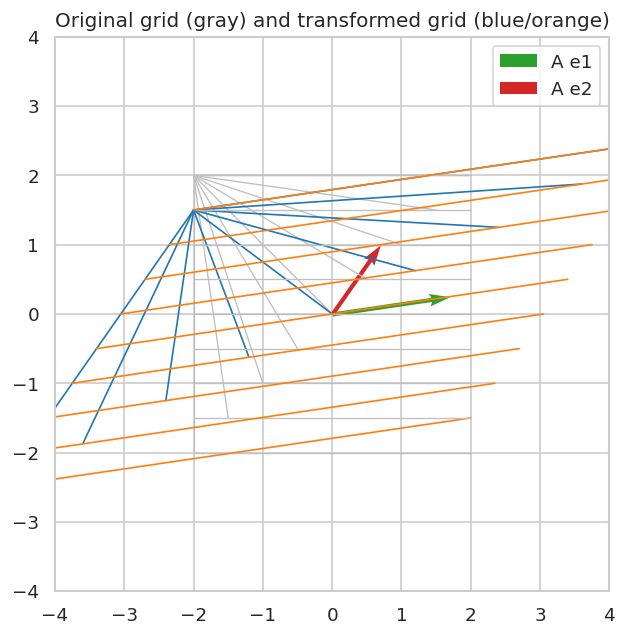

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_mat_A = np.array([[1.7, 0.7], [0.25, 1.0]])
viz_mat_grid = np.linspace(-2, 2, 9)
fig, ax = plt.subplots(figsize=(7, 6))
for viz_mat_t in viz_mat_grid:
    p = np.array([[viz_mat_t, -2], [viz_mat_t, 2]])
    q = viz_mat_A @ p
    ax.plot(p[0], p[1], color="0.75", lw=0.8)
    ax.plot(q[0], q[1], color="tab:blue", lw=1.0)
    p2 = np.array([[-2, 2], [viz_mat_t, viz_mat_t]])
    q2 = viz_mat_A @ p2
    ax.plot(p2[0], p2[1], color="0.75", lw=0.8)
    ax.plot(q2[0], q2[1], color="tab:orange", lw=1.0)
for viz_basis, viz_lab, viz_col in [(np.array([1., 0.]), "A e1", "tab:green"), (np.array([0., 1.]), "A e2", "tab:red")]:
    viz_image = viz_mat_A @ viz_basis
    ax.quiver(0, 0, viz_image[0], viz_image[1], angles="xy", scale_units="xy", scale=1, color=viz_col, label=viz_lab)
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal", adjustable="box")
ax.set_title("Original grid (gray) and transformed grid (blue/orange)"); ax.legend(); plt.show()
display(pd.DataFrame(viz_mat_A, index=["row 1", "row 2"], columns=["column 1", "column 2"]))

### Solve a linear system rather than explicitly inverting the matrix

For a system \(A\mathbf{x}=\mathbf{b}\), prefer `np.linalg.solve(A, b)` over `np.linalg.inv(A) @ b`. The direct solve is clearer and usually more numerically appropriate. A singular or nearly singular matrix needs special care; check rank and conditioning when results look unstable.

solution: [1.04918033 1.73770492]
reconstructed right-hand side: [3. 2.]
residual norm: 0.0
rank: 2 determinant: 1.525


02_matrices_and_linear_systems.ipynb:cell16:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


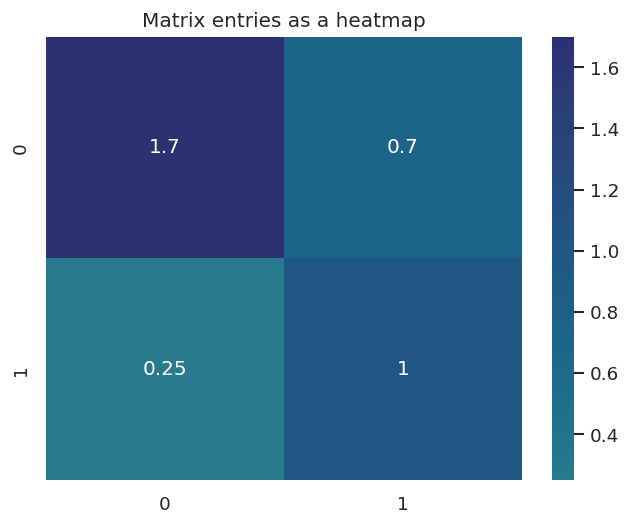

In [7]:
viz_mat_b = np.array([3.0, 2.0])
viz_mat_solution = np.linalg.solve(viz_mat_A, viz_mat_b)
print("solution:", viz_mat_solution)
print("reconstructed right-hand side:", viz_mat_A @ viz_mat_solution)
print("residual norm:", np.linalg.norm(viz_mat_A @ viz_mat_solution - viz_mat_b))
print("rank:", np.linalg.matrix_rank(viz_mat_A), "determinant:", round(np.linalg.det(viz_mat_A), 3))
sns.heatmap(viz_mat_A, annot=True, cmap="crest", center=0)
plt.title("Matrix entries as a heatmap"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Multiply a 2x3 matrix by a compatible 3x1 vector.

In [8]:
A = np.array([[1, 2, 3], [4, 5, 6]])
x = np.array([1, 0, -1])
print(A @ x)

[-2 -2]


### Exercise 2
Exercise 2: Fit the least-squares line y = b0 + b1*x for three data points.

In [9]:
x = np.array([0.0, 1.0, 2.0])
y = np.array([1.0, 2.0, 2.5])
X = np.column_stack([np.ones_like(x), x])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
print("intercept, slope:", beta)

intercept, slope: [1.08333333 0.75      ]


## Key takeaways
- Matrix multiplication requires compatible inner dimensions.
- Rank describes linear independence; determinant is defined only for square matrices.
- Solve systems directly and inspect residuals when numerical reliability matters.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.